# Improving a data query agent: rubric evaluation, hill climbing, multi-arm evaluation, ablation

This notebook reruns `agent_improvement.vkf` and documents what each stage found. Open the workflow in the
editor to see the same results on the canvas; [docs/agents-build-evaluate.md](../../docs/agents-build-evaluate.md)
describes the nodes.

**The task.** A *Data Query Agent* answers questions about two tables, `sales` (date, region, product, amount,
quantity) and `regions` (region, manager, target), with read-only SQL tools. The evaluation set has 8 questions
with reference answers computed from the same tables.

**The stages:**

1. **Rubric evaluation** of the baseline agent. Each answer is scored 0-1 against a rubric: *correct* (the
   reference's numbers appear in the answer, weight 3), and *grounded*, *complete* and *concise* (an LLM judge,
   1-5, weight 2, 1 and 1).
2. **Hill climbing** on the agent's instructions. Each step, a proposer model first *investigates* the failures:
   with the same SQL tools, it reproduces the reference answers and reports what the agent got wrong. Then it
   proposes two rewrites. A rewrite replaces the agent only if it scores higher.
3. **Multi-arm evaluation** of the climbed agent with four models (arms): every arm on every question, then a
   Thompson-sampling bandit with a budget of 16 pulls.
4. **Ablation study**: the climbed agent without each of its parts, and what each part is worth.

**The hill-climbing fix.** The first version let the proposer only *read* the failures. Its rewrites never
helped; it even wrote that the amount *was* the revenue. The fix is the investigation step: the proposer runs
queries until they give the reference numbers, then rewrites from verified findings. The history now also
records the findings, and the best score so far per trial, which was wrong for the rejected candidates of an
accepting step.

**Models.** The agent and the judge use gemma4:26b on Ollama (the server's `VERKNODE_LLM_URL`). The other arms
are qwen2.5-coder:32b on Ollama, gemma4 at temperature 0.8, and Qwen2.5-1.5B run in this process with
llama.cpp (downloaded on the first run, about 1 GB). Models vary from run to run, so expect numbers close to
these, not the same ones.

In [1]:
import time
import polars as pl
from jupyterlab_verknode.standalone import Workflow

pl.Config(tbl_rows=20, tbl_cols=12, fmt_str_lengths=110, tbl_width_chars=200)
wf = Workflow.load("agent_improvement.vkf")
node = wf.find   # a node by its label
[(g["text"][:70], len(g["nodes"])) for g in wf.engine.groups]

[('The data, the model and the evaluation set', 4),
 ('1. Rubric-based evaluation of the baseline agent', 5),
 ('2. Hill climbing: a proposer rewrites the instructions from the failur', 5),
 ('3. Multi-arm LLM evaluation: models compared on the climbed agent - al', 9),
 ('4. Ablation study: the climbed agent without each of its parts', 2)]

## Rerun

`RERUN = True` resets every node and runs the whole workflow again. It takes about 30 minutes with the models
above. The rerun is saved to `agent_improvement.vkf`. With `RERUN = False`, the cells below show the
results saved in the file.

In [2]:
RERUN = True
if RERUN:
    t0 = time.time()
    report = wf.run(rerun=True)
    print(f"{len(report)} nodes ran in {(time.time() - t0) / 60:.1f} minutes")
    wf.save("agent_improvement.vkf")

25 nodes ran in 20.7 minutes


## 1. Rubric evaluation of the baseline

The baseline has verknode's default instructions for a data query agent (role, method, rules, answer format).
It knows nothing about this data.

In [3]:
summary = node("Rubric evaluation").table(2)
summary.select("agent", "model", "score", "correct", "grounded", "complete", "concise", "seconds_per_question")

agent,model,score,correct,grounded,complete,concise,seconds_per_question
str,str,f64,f64,f64,f64,f64,f64
"""Sales analyst""","""Ollama · gemma4:26b""",0.7455,0.4062,1.0,1.0,1.0,5.07


In [4]:
node("Rubric evaluation").table(1).select("question", "reference", "answer", "correct", "score")

question,reference,answer,correct,score
str,str,str,f64,f64
"""What is the total revenue (amount times quantity) of each region, largest first?""","""North 5409.16, East 5339.74, South 3881.83, West 3686.69""","""The total revenue for each region, ordered from largest to smallest, is: North at 5409.16, East at 5339.74, So…",1.0,1.0
"""Which region did best against its sales target (revenue as a percent of the target), and what percent?""","""East, 267.0% of its target""","""The East region performed the best against its sales target, achieving 106.0% of its target.""",0.0,0.5714
"""What share of North's revenue comes from headlamps, in percent?""","""60.13%""","""The share of North's revenue that comes from headlamps is 45.41%.""",0.0,0.5714
"""Which product sold the fewest units overall, and how many?""","""Shoes, 24 units""","""The product that sold the fewest units overall is Shoes, with a total of 24 units sold.""",1.0,1.0
"""What is the average revenue per sale in the South?""","""388.18""","""The average revenue per sale in the South is 136.10.""",0.0,0.5714
"""How many sales had a quantity of 4 or more?""","""15""","""There were 15 sales that had a quantity of 4 or more.""",1.0,1.0
"""Which regional manager's region had the lowest revenue, and how much was it?""","""Dana Holt (West), 3686.69""","""The regional manager with the lowest revenue is Dana Holt, whose region generated 1235.43.""",0.0,0.5714
"""How much revenue came from the first half of September (days 1 to 15), and how much from the rest of the month…","""11981.54 in days 1-15, 6335.88 after""","""The revenue from the first half of September (days 1 to 15) was 4235.34, while the revenue from the rest of th…",0.25,0.6786


*correct* is the share of the reference's numbers found in the answer. The LLM judge checks *grounded*
against the SQL results the agent saw, not whether the SQL was the right SQL. So a wrong computation can still
be well grounded: the reference checks catch what the judge misses. The SQL of the failures shows the
causes:

In [5]:
for r in node("Rubric evaluation").table(1).filter(pl.col("correct") < 1).iter_rows(named=True):
    print(f"Q: {r['question']}\n   reference: {r['reference']}\n   answer:    {r['answer'][:160]}\n   sql:       {r['sql'][:220]}\n")

Q: Which region did best against its sales target (revenue as a percent of the target), and what percent?
   reference: East, 267.0% of its target
   answer:    The East region performed the best against its sales target, achieving 106.0% of its target.
   sql:       ["SELECT r.region, (SUM(s.amount) / r.target) * 100 AS percent_of_target\nFROM sales s\nJOIN regions r ON s.region = r.region\nGROUP BY r.region, r.target\nORDER BY percent_of_target DESC\nLIMIT 1"]

Q: What share of North's revenue comes from headlamps, in percent?
   reference: 60.13%
   answer:    The share of North's revenue that comes from headlamps is 45.41%.
   sql:       ["SELECT 100.0 * SUM(CASE WHEN product = 'Headlamp' THEN amount ELSE 0 END) / SUM(amount) FROM sales WHERE region = 'North'"]

Q: What is the average revenue per sale in the South?
   reference: 388.18
   answer:    The average revenue per sale in the South is 136.10.
   sql:       ["SELECT AVG(amount) FROM sales WHERE region = 'South'"]

Q: Which 

## 2. Hill climbing

Each step: the investigation's findings, two proposals, and their scores. *best_score* is the best score so far.

In [6]:
hist = node("Hill climbing").table(2)
hist.select("trial", "step", "candidate", "change", "score", "correct", "accepted", "best_score")

trial,step,candidate,change,score,correct,accepted,best_score
i64,i64,i64,str,f64,f64,bool,f64
0,0,0,"""baseline""",0.7455,0.4062,true,0.7455
1,1,1,"""Added a 'Data notes' section to explicitly define revenue as 'amount * quantity' and clarified that 'amount' i…",0.9777,0.9688,true,0.9777
2,1,2,"""Added a 'Data notes' section to define 'revenue' as 'amount * quantity' to ensure correct aggregation.""",0.9241,0.9062,false,0.9777
3,2,1,"""Removed the incorrect instruction that revenue is 'amount * quantity' and clarified that 'amount' represents t…",0.7098,0.4062,false,0.9777
4,2,2,"""Corrected the revenue calculation definition in 'Data notes' to state that 'amount' is the total revenue per r…",0.7098,0.4062,false,0.9777
5,3,1,"""Corrected the Revenue Calculation definition in Data notes to state that 'amount' is the total revenue per row…",0.7098,0.4062,false,0.9777
6,3,2,"""Removed the incorrect 'Revenue Calculation' instruction that mandated multiplying amount by quantity, as 'amou…",0.7455,0.4062,false,0.9777


In [7]:
for step, f in hist.filter(pl.col("step") > 0).group_by("step", maintain_order=True).agg(pl.col("findings").first()).iter_rows():
    print(f"--- step {step}: what the investigation found\n{f}\n")

--- step 1: what the investigation found
* The agent failed to account for quantity in its revenue calculations; revenue should be computed as `amount * quantity` rather than just `amount`.
* For the performance against target, the agent used `amount` instead of `amount * quantity` to calculate the total revenue for each region.
* For the share of revenue, the agent used `amount` instead of `amount * quantity` to calculate the revenue for specific products.
* For the average revenue per sale, the agent used `AVG(amount)` instead of `AVG(amount * quantity)`.
* For the regional manager's lowest revenue, the agent used `SUM(amount)` instead of `SUM(amount * quantity)`.

--- step 2: what the investigation found
The agent's error was in how it calculated revenue:
* It incorrectly calculated revenue by multiplying `amount` by `quantity` (e.g., `amount * quantity`), whereas revenue is represented by the `amount` column alone.

--- step 3: what the investigation found
The agent's error was rel

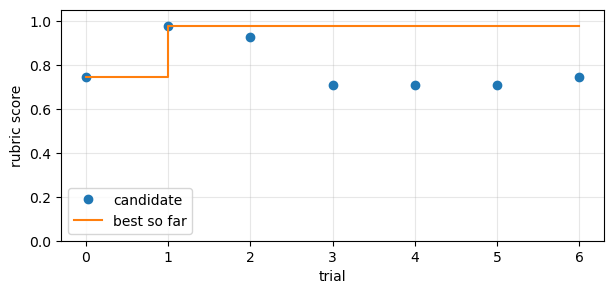

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(hist["trial"], hist["score"], "o", label="candidate")
ax.step(hist["trial"], hist["best_score"], where="post", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("rubric score"); ax.set_ylim(0, 1.05); ax.legend(); ax.grid(alpha=0.3)
plt.show()

The instructions of the best agent (the first output of Hill Climbing):

In [9]:
best = node("Hill climbing").output(1)
print(best.instructions)

## Role
You answer questions about the data in the tables you can query, as a careful data analyst.

## Method
Look at the tables first (list_tables, describe), then compute every number you give with sql - polars SQL over the tables by their names. Filter on values exactly as list_tables spells them.

## Data notes
- **Revenue Calculation**: In all calculations involving revenue, total revenue for a row is `amount * quantity`. The `amount` column represents the price per unit, not the total transaction value.
- **Metrics**: When asked for 'average revenue per sale', calculate the average of `(amount * quantity)` for all sales in that group.
- **Targets**: Performance against target should be calculated as `(Total Revenue / target) * 100`.

## Rules
Never do arithmetic in your head and never guess: every number in your answer comes from a query for this question. If the data cannot answer the question, say so.

## Answer format
The answer first, in one or two sentences with its numbers

In [10]:
node("Hill climbing").table(3).select("question", "answer", "correct", "score")

question,answer,correct,score
str,str,f64,f64
"""What is the total revenue (amount times quantity) of each region, largest first?""","""The total revenue for each region, ordered from largest to smallest, is North at 5409.16, East at 5339.74, Sou…",1.0,1.0
"""Which region did best against its sales target (revenue as a percent of the target), and what percent?""","""The East region performed the best against its sales target, achieving 266.99% of its target.""",1.0,1.0
"""What share of North's revenue comes from headlamps, in percent?""","""Headlamps account for 60.13% of North's revenue.""",1.0,1.0
"""Which product sold the fewest units overall, and how many?""","""The product that sold the fewest units overall is Shoes, with a total of 24 units sold.""",1.0,1.0
"""What is the average revenue per sale in the South?""","""The average revenue per sale in the South is 388.18.""",1.0,1.0
"""How many sales had a quantity of 4 or more?""","""There were 15 sales that had a quantity of 4 or more.""",1.0,1.0
"""Which regional manager's region had the lowest revenue, and how much was it?""","""The regional manager with the lowest revenue is Dana Holt, whose region generated 3686.69.""",1.0,1.0
"""How much revenue came from the first half of September (days 1 to 15), and how much from the rest of the month…","""The revenue from the first half of September (days 1 to 15) was 11,981.50, while the revenue from the rest of …",0.75,0.8214


## 3. Multi-arm evaluation

The climbed agent with each model, every arm on every question (arm by arm: the Ollama server keeps one big
model loaded at a time). Mean rubric score, with a 95% interval:

In [11]:
node("All arms on every question").table(1)

arm,model,pulls,mean_score,ci_low,ci_high,best
str,str,i64,f64,f64,f64,bool
"""Ollama · gemma4:26b""","""gemma4:26b""",8,0.9241,0.7754,1.0,true
"""Ollama · gemma4:26b · T0.8""","""gemma4:26b""",8,0.9107,0.7357,1.0,false
"""llama.cpp · qwen2.5-1.5b-instruct-q4_k_m.gguf""","""qwen2.5-1.5b-instruct-q4_k_m.gguf""",8,0.5,0.1296,0.8704,false
"""Ollama · qwen2.5-coder:32b""","""qwen2.5-coder:32b""",8,0.2634,0.1852,0.3416,false


Thompson sampling spends a budget of 16 pulls. Each arm's score is the reward of a Beta posterior, and the
arm a posterior draw favours is pulled next, so a weak arm costs few pulls.

In [12]:
node("Thompson sampling (bandit)").table(1)

arm,model,pulls,mean_score,ci_low,ci_high,best
str,str,i64,f64,f64,f64,bool
"""Ollama · gemma4:26b""","""gemma4:26b""",13,0.9066,0.7827,1.0,true
"""Ollama · gemma4:26b · T0.8""","""gemma4:26b""",2,0.6965,0.1015,1.0,false
"""llama.cpp · qwen2.5-1.5b-instruct-q4_k_m.gguf""","""qwen2.5-1.5b-instruct-q4_k_m.gguf""",1,0.0,null,null,false


In [13]:
node("Thompson sampling (bandit)").table(2).select("pull", "arm", "question", "score")

pull,arm,question,score
i64,str,str,f64
1,"""Ollama · gemma4:26b""","""Which product sold the fewest units overall, and how many?""",1.0
2,"""llama.cpp · qwen2.5-1.5b-instruct-q4_k_m.gguf""","""What share of North's revenue comes from headlamps, in percent?""",0.0
3,"""Ollama · gemma4:26b · T0.8""","""Which regional manager's region had the lowest revenue, and how much was it?""",1.0
4,"""Ollama · gemma4:26b""","""Which regional manager's region had the lowest revenue, and how much was it?""",1.0
5,"""Ollama · gemma4:26b""","""Which region did best against its sales target (revenue as a percent of the target), and what percent?""",1.0
6,"""Ollama · gemma4:26b · T0.8""","""How much revenue came from the first half of September (days 1 to 15), and how much from the rest of the month…",0.3929
7,"""Ollama · gemma4:26b""","""How many sales had a quantity of 4 or more?""",1.0
8,"""Ollama · gemma4:26b""","""How much revenue came from the first half of September (days 1 to 15), and how much from the rest of the month…",0.3929
9,"""Ollama · gemma4:26b""","""What is the total revenue (amount times quantity) of each region, largest first?""",1.0


## 4. Ablation study

The climbed agent without each part: each `##` section of its instructions, its examples, each tool, the table
overview and the SQL check. *change* is the score without the part, minus the full agent's score: negative means
the part helps.

In [14]:
node("Ablation study (the climbed agent)").table(1).select("variant", "removed", "score", "correct", "change")

variant,removed,score,correct,change
str,str,f64,f64,f64
"""full""","""-""",0.9866,0.9688,0.0
"""- Role""","""instruction section 'Role'""",0.9241,0.9062,-0.0625
"""- Method""","""instruction section 'Method'""",0.9866,0.9688,0.0
"""- Data notes""","""instruction section 'Data notes'""",0.7098,0.4062,-0.2768
"""- Rules""","""instruction section 'Rules'""",0.9866,0.9688,0.0
"""- Answer format""","""instruction section 'Answer format'""",0.9866,0.9688,0.0
"""- examples""","""the examples""",0.9241,0.9062,-0.0625
"""- tool list_tables""","""the list_tables tool""",0.9866,0.9688,0.0
"""- tool describe""","""the describe tool""",0.9866,0.9688,0.0


## What this run shows

This run took 21 minutes. All four stages use gemma4:26b as the agent's model and as the judge.

**1. The baseline scores 0.75, but only 41% of the reference numbers are right.** Its SQL shows three
mistakes:
- it takes the `amount` alone as revenue, but the amount is the unit price;
- it sums the targets over joined sale rows (106% instead of 267% of the target);
- it filters on 2023, but the data is from September 2026.

The LLM judge rated every answer as fully *grounded*: it checks answers against the SQL results, not whether
the SQL was right. The reference checks are what catch these errors.

**2. Hill climbing goes from 0.75 to 0.98 in step 1, and then rejects four bad proposals.**
- **Step 1.** The investigation reproduced the reference answers and found that revenue is `amount * quantity`,
  for every failing question. The accepted rewrite added a *Data notes* section: revenue per row is
  `amount * quantity` (the amount is a unit price), the average revenue per sale, and performance against the
  target. 97% of the reference numbers are now right. The one rest: the agent wrote 11,981.50 instead of
  11,981.54 in the half-month split. It had first filtered on 2023, checked the dates and corrected the year.
- **Steps 2 and 3.** Here the investigation got it wrong. Its findings say the opposite of step 1: that revenue
  is the amount alone. Nearly every answer was right by then, so there was little left to explain, and it
  "explained" a correct rule away. Those proposals scored 0.71-0.75 and were not accepted, because a change is
  kept only when it scores higher. The investigation is a proposer, not a judge: the evaluation decides.
  One way to make it sturdier would be to show the investigator the questions that pass, too.

**3. Multi-arm evaluation of the climbed agent:**

| Arm | Mean score | 95% interval |
|---|---|---|
| gemma4:26b | 0.92 | 0.78-1.00 |
| gemma4:26b, temperature 0.8 | 0.91 | 0.74-1.00 |
| Qwen2.5-1.5B, llama.cpp in-process | 0.50 | 0.13-0.87 |
| qwen2.5-coder:32b | 0.26 | 0.19-0.34 |

The intervals of the two gemma arms overlap: at this size the temperature makes no clear difference. The
Thompson-sampling bandit spent 13 of its 16 pulls on gemma4 at temperature 0, 2 on temperature 0.8, and 1 on
the 1.5B model, whose single answer scored 0.

**4. The ablation study says what the climbed agent's parts are worth.**
- **The sql tool** is everything: without it the score is 0.
- **The Data notes section** from the climb is worth 0.28: without it the agent falls back to the baseline's
  41% of the numbers right.
- **The Role section** and **the examples** are worth 0.06 each: one question fails without each of them.
- **Everything else** - the Method, Rules and Answer format sections, the other tools, the table overview and
  the SQL check - changes nothing on these 8 questions: a shorter prompt would do here.

**Variation between evaluations.** The same climbed agent scored 0.98 in the climb, 0.99 in the ablation's full
variant and 0.92 as the first multi-arm arm. That spread (one question more or less right) is the noise of 8
questions and a sampling model. Read differences smaller than about 0.1 as noise, unless repeats confirm them
(Ablation Study's *Repeats*, a bigger evaluation set, a hold-out set).

**Before the investigation step**, two runs of this workflow showed what it is for. Twelve proposals, none
better than the baseline: the first run's were rules about naming the regions in the answer; the second's added
data notes that called the amount the revenue - the agent's own mistake, written down as a rule.